# Optimización de rutas: TSP y m-TSP

Este cuaderno resuelve problemas de **rutas** con **modelos de optimización** (programación lineal entera mixta) y un solver exacto (**HiGHS**, vía SciPy).

**Qué incluye**
- **TSP** (viajante de comercio): un recorrido que visita cada punto una vez y regresa al origen, con el costo mínimo.
- **m-TSP**: `m` vehículos que salen y regresan al depósito, con un número mínimo y máximo de clientes por vehículo, y dos objetivos: distancia total o ruta más larga.
- **Camino mínimo** como programa lineal de flujo en red, para comparar con el TSP.

**Qué no incluye (por diseño)**
- No usa algoritmos de grafos (como Dijkstra, Prim, Kruskal o Floyd).
- No usa heurísticas ni búsquedas aproximadas. Cuando el solver termina, el resultado es **óptimo demostrado** (brecha MIP = 0), o se informa explícitamente que se detuvo por tiempo.

**Cómo se resuelve el TSP:** modelo de asignación (cada punto tiene exactamente una salida y una entrada) más restricciones de eliminación de subtours añadidas en cada iteración (Dantzig, Fulkerson y Johnson, 1954). Cada iteración resuelve el modelo entero con HiGHS, y el ciclo termina cuando la solución es un único recorrido.

## 0. Requisitos

```bash
pip install numpy pandas scipy matplotlib openpyxl ipywidgets
```

Ejecute las celdas en orden. El panel de la sección 5 permite cambiar parámetros sin tocar el código.

In [1]:
import time, itertools, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import milp, linprog, LinearConstraint, Bounds
from scipy.sparse import lil_matrix, csr_matrix
import scipy

print("scipy", scipy.__version__, "| solver: HiGHS (scipy.optimize.milp / linprog)")

scipy 1.18.1 | solver: HiGHS (scipy.optimize.milp / linprog)


## 1. Datos

Se aceptan dos formatos:
- **Matriz de distancias** (CSV o Excel): una fila por punto, primera columna con el nombre del punto.
- **Coordenadas** (CSV con `id, nombre, latitud, longitud`): la distancia se calcula como Haversine × factor vial.

Los datos de ejemplo están en la carpeta `datos/`. **Por defecto el modelo usa la matriz por carretera.** Si solo tiene coordenadas, `matriz_desde_coordenadas` calcula la línea recta, que subestima la distancia de recorrido; use un factor vial si no tiene la matriz por carretera.

In [2]:
def haversine_km(lat1, lon1, lat2, lon2, R=6371.0088):
    p1, p2 = math.radians(lat1), math.radians(lat2)
    dphi, dl = p2 - p1, math.radians(lon2 - lon1)
    a = math.sin(dphi / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(dl / 2) ** 2
    return 2 * R * math.asin(math.sqrt(a))

def matriz_desde_coordenadas(df, factor_vial=1.0):
    n = len(df)
    D = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            if i != j:
                D[i, j] = factor_vial * haversine_km(df.latitud[i], df.longitud[i], df.latitud[j], df.longitud[j])
    return D

def cargar_matriz(ruta):
    """Lee una matriz de distancias (CSV o Excel). La primera columna son los nombres de los puntos."""
    ext = str(ruta).lower().rsplit(".", 1)[-1]
    df = pd.read_excel(ruta, index_col=0) if ext in ("xlsx", "xls") else pd.read_csv(ruta, index_col=0)
    nombres = [str(x) for x in df.index]
    D = df.to_numpy(dtype=float)
    if D.shape[0] != D.shape[1]:
        raise ValueError("La matriz debe ser cuadrada (una fila y una columna por punto).")
    np.fill_diagonal(D, 0.0)
    return D, nombres

def cargar_coordenadas(ruta, factor_vial=1.0):
    df = pd.read_csv(ruta)
    df = df.rename(columns=lambda c: c.strip().lower())
    return df, matriz_desde_coordenadas(df, factor_vial)

# Datos de ejemplo: 26 puntos de Cali (centro de distribución y tiendas)
tiendas, D_linea = cargar_coordenadas("datos/tiendas_cali.csv")       # línea recta (Haversine, factor 1)
D_cali, nombres_cali = cargar_matriz("datos/distancias_cali_km.csv")  # distancias por carretera (predeterminada)
print("Puntos:", len(tiendas))
print("Carretera vs. línea recta: total de la matriz por carretera =", round(float(D_cali.sum()) / 2, 1),
      "km; por línea recta =", round(float(D_linea.sum()) / 2, 1), "km")
tiendas.head()

Puntos: 26
Carretera vs. línea recta: total de la matriz por carretera = 2293.9 km; por línea recta = 1660.0 km


,id,nombre,latitud,longitud
0,0,CD central (provisional),3.425415,-76.514309
1,1,Cali - VALLE GRANDE,3.394598,-76.524377
2,2,Cali - LOS ALAMOS,3.478631,-76.516804
3,3,Cali - PORVENIR CALI,3.424276,-76.511981
4,4,Cali - Quintas Don Simon,3.387378,-76.532607


## 2. Modelo TSP

**Variables:** $x_{ij} \in \{0,1\}$, igual a 1 si el recorrido va del punto $i$ al $j$.

**Función objetivo:**
$$\min \sum_{i \ne j} d_{ij}\, x_{ij}$$

**Restricciones:**
$$\sum_{j \ne i} x_{ij} = 1, \qquad \sum_{j \ne i} x_{ji} = 1 \qquad \forall i$$

**Eliminación de subtours** (cada subconjunto propio $S$ no puede cerrar un ciclo por sí solo):
$$\sum_{i,j \in S,\, i \ne j} x_{ij} \le |S| - 1$$

Estas últimas se añaden solo cuando la solución tiene más de un ciclo.

In [3]:
def _componentes(n, arcos):
    padre = list(range(n))
    def raiz(a):
        while padre[a] != a:
            padre[a] = padre[padre[a]]
            a = padre[a]
        return a
    for i, j in arcos:
        padre[raiz(i)] = raiz(j)
    grupos = {}
    for v in range(n):
        grupos.setdefault(raiz(v), []).append(v)
    return list(grupos.values())

def resolver_tsp(D, origen=0, tiempo_limite=120, brecha=1e-6, verbose=False):
    """TSP exacto: modelo entero + restricciones de subtours añadidas iterativamente."""
    D = np.asarray(D, float)
    n = D.shape[0]
    arcos = [(i, j) for i in range(n) for j in range(n) if i != j]
    idx = {a: k for k, a in enumerate(arcos)}
    m = len(arcos)
    c = np.array([D[i, j] for i, j in arcos])
    filas, lo, hi = [], [], []
    for i in range(n):
        filas.append({idx[(i, j)]: 1 for j in range(n) if j != i}); lo.append(1); hi.append(1)
        filas.append({idx[(j, i)]: 1 for j in range(n) if j != i}); lo.append(1); hi.append(1)
    cortes, t0 = 0, time.time()
    while True:
        A = lil_matrix((len(filas), m))
        for r, co in enumerate(filas):
            for k, v in co.items():
                A[r, k] = v
        restante = max(1.0, tiempo_limite - (time.time() - t0))
        res = milp(c, constraints=LinearConstraint(csr_matrix(A), lo, hi),
                   integrality=np.ones(m), bounds=Bounds(0, 1),
                   options={"time_limit": restante, "mip_rel_gap": brecha, "disp": verbose})
        if res.x is None:
            return {"estado": "sin solución", "detalle": res.message}
        x = np.round(res.x).astype(int)
        seleccion = [arcos[k] for k in range(m) if x[k] == 1]
        componentes = _componentes(n, seleccion)
        if len(componentes) == 1:
            break
        for S in componentes:
            co = {idx[(i, j)]: 1 for i in S for j in S if i != j}
            filas.append(co); lo.append(0); hi.append(len(S) - 1); cortes += 1
    sucesor = {i: j for i, j in seleccion}
    ruta, cur = [origen], sucesor[origen]
    while cur != origen:
        ruta.append(cur); cur = sucesor[cur]
    ruta.append(origen)
    return {"estado": "óptimo" if res.status == 0 else "detenido por tiempo",
            "valor": float(res.fun), "ruta": ruta, "cortes_subtour": cortes,
            "brecha_mip": getattr(res, "mip_gap", None), "segundos": round(time.time() - t0, 2)}

r_tsp = resolver_tsp(D_cali, origen=0)
print(r_tsp["estado"], "| costo:", round(r_tsp["valor"], 3), "km | cortes:", r_tsp["cortes_subtour"],
      "| brecha:", r_tsp["brecha_mip"], "|", r_tsp["segundos"], "s")
print("Ruta (índices):", " > ".join(map(str, r_tsp["ruta"])))

óptimo | costo: 72.048 km | cortes: 23 | brecha: 0.0 | 0.09 s
Ruta (índices): 0 > 3 > 12 > 1 > 16 > 4 > 17 > 6 > 22 > 18 > 14 > 8 > 20 > 13 > 5 > 15 > 9 > 10 > 24 > 2 > 19 > 25 > 21 > 7 > 23 > 11 > 0


## 3. Modelo m-TSP

Con $m$ vehículos, cada uno sale del depósito, visita un subconjunto de clientes y regresa.

**Variables:**
- $x_{ijk} \in \{0,1\}$: el vehículo $k$ recorre el arco $i \to j$.
- $y_{ik} \in \{0,1\}$: el cliente $i$ es atendido por el vehículo $k$.

**Restricciones principales:**
- Cada cliente se atiende por exactamente un vehículo: $\sum_k y_{ik} = 1$.
- Cada vehículo sale y regresa una vez al depósito.
- Balance: $L_{\min} \le \sum_i y_{ik} \le L_{\max}$ para cada vehículo. Este límite evita soluciones degeneradas, como un vehículo que solo visita un cliente.
- Flujo: lo que entra y lo que sale de un cliente en el vehículo $k$ es $y_{ik}$.
- Eliminación de subtours por vehículo: $\sum_{i,j \in S} x_{ijk} \le \sum_{i \in S,\, i \ne h} y_{ik}$.

**Objetivos:**
- `suma`: $\min \sum_{i,j,k} d_{ij}\, x_{ijk}$ (distancia total).
- `maximo`: $\min z$ con $\sum_{i,j} d_{ij}\, x_{ijk} \le z$ para cada vehículo (equilibrio de la ruta más larga).

In [4]:
def resolver_mtsp(D, m, origen=0, lmin=1, lmax=None, objetivo="suma", tiempo_limite=300, brecha=1e-6, verbose=False):
    """m-TSP exacto con balance de clientes por vehículo."""
    D = np.asarray(D, float)
    n = D.shape[0]
    clientes = [i for i in range(n) if i != origen]
    lmax = lmax or len(clientes)
    if not (1 <= lmin <= lmax):
        raise ValueError("Se requiere 1 <= lmin <= lmax.")
    if m * lmin > len(clientes) or m * lmax < len(clientes):
        raise ValueError("Con estos límites no hay reparto posible de los clientes entre los vehículos.")
    arcos = [(i, j) for i in range(n) for j in range(n) if i != j]
    K = range(m)
    x_idx = {(i, j, k): t for t, (i, j, k) in enumerate((i, j, k) for (i, j) in arcos for k in K)}
    y_idx = {(i, k): len(x_idx) + t for t, (i, k) in enumerate((i, k) for i in clientes for k in K)}
    nx_, ny_ = len(x_idx), len(x_idx) + len(y_idx)
    z_idx = ny_ if objetivo == "maximo" else None
    nv = ny_ + (1 if z_idx is not None else 0)
    c = np.zeros(nv)
    for (i, j, k), t in x_idx.items():
        c[t] = D[i, j] if objetivo == "suma" else 0.0
    if z_idx is not None:
        c[z_idx] = 1.0
    filas, lo, hi = [], [], []
    def agregar(co, l, u):
        filas.append(co); lo.append(l); hi.append(u)
    for i in clientes:
        agregar({y_idx[(i, k)]: 1 for k in K}, 1, 1)
    for k in K:
        agregar({x_idx[(origen, j, k)]: 1 for j in clientes}, 1, 1)
        agregar({x_idx[(i, origen, k)]: 1 for i in clientes}, 1, 1)
        agregar({y_idx[(i, k)]: 1 for i in clientes}, lmin, lmax)
        for i in clientes:
            agregar({**{x_idx[(j, i, k)]: 1 for j in range(n) if j != i}, y_idx[(i, k)]: -1}, 0, 0)
            agregar({**{x_idx[(i, j, k)]: 1 for j in range(n) if j != i}, y_idx[(i, k)]: -1}, 0, 0)
        if z_idx is not None:
            co = {x_idx[(i, j, k)]: D[i, j] for (i, j) in arcos}
            co[z_idx] = -1
            agregar(co, -np.inf, 0)
    integ = np.zeros(nv); integ[:ny_] = 1
    ub = np.full(nv, np.inf); ub[:ny_] = 1
    cortes, t0 = 0, time.time()
    while True:
        A = lil_matrix((len(filas), nv))
        for r, co in enumerate(filas):
            for col, v in co.items():
                A[r, col] = v
        restante = max(1.0, tiempo_limite - (time.time() - t0))
        res = milp(c, constraints=LinearConstraint(csr_matrix(A), lo, hi), integrality=integ,
                   bounds=Bounds(np.zeros(nv), ub),
                   options={"time_limit": restante, "mip_rel_gap": brecha, "disp": verbose})
        if res.x is None:
            return {"estado": "sin solución", "detalle": res.message}
        x = np.round(res.x[:nx_]).astype(int)
        violado = False
        rutas_arcos = {}
        for k in K:
            sel = [(i, j) for (i, j) in arcos if x[x_idx[(i, j, k)]] == 1]
            rutas_arcos[k] = sel
            for S in _componentes(n, sel):
                if origen in S or len(S) < 2:
                    continue
                violado = True
                h = S[0]
                co = {x_idx[(i, j, k)]: 1 for i in S for j in S if i != j}
                for i in S:
                    if i != h:
                        co[y_idx[(i, k)]] = co.get(y_idx[(i, k)], 0) - 1
                agregar(co, -np.inf, 0); cortes += 1
        if not violado:
            break
    def secuencia(sel):
        sucesores = {}
        for i, j in sel:
            sucesores.setdefault(i, []).append(j)
        ruta, cur = [origen], sucesores[origen][0]
        while cur != origen:
            ruta.append(cur); cur = sucesores[cur][0]
        return ruta + [origen]
    rutas = []
    for k in K:
        r = secuencia(rutas_arcos[k])
        rutas.append({"vehiculo": k + 1, "ruta": r, "clientes": len(r) - 2,
                      "distancia_km": float(sum(D[a, b] for a, b in zip(r[:-1], r[1:])))})
    return {"estado": "óptimo" if res.status == 0 else "detenido por tiempo",
            "valor": float(res.fun), "rutas": rutas, "cortes_subtour": cortes,
            "brecha_mip": getattr(res, "mip_gap", None), "segundos": round(time.time() - t0, 2)}

r_m2 = resolver_mtsp(D_cali, m=2, lmin=12, lmax=13, objetivo="suma")
print(r_m2["estado"], "| costo total:", round(r_m2["valor"], 3), "km | cortes:", r_m2["cortes_subtour"],
      "| brecha:", r_m2["brecha_mip"], "|", r_m2["segundos"], "s")
pd.DataFrame(r_m2["rutas"])

óptimo | costo total: 75.675 km | cortes: 60 | brecha: 0.0 | 45.88 s


,vehiculo,ruta,clientes,distancia_km
0,1,"[0, 23, 7, 21, 25, 19, 2, 24, 10, 15, 9, 11, 3...",12,32.658
1,2,"[0, 12, 1, 16, 4, 17, 6, 22, 18, 14, 20, 13, 5...",13,43.017


## 4. Camino mínimo como programa lineal

Se modela el envío de una unidad de flujo del origen al destino con costo mínimo. Las restricciones de conservación de flujo hacen que la solución sea un camino. El problema es totalmente unimodular, así que el solver entrega una solución entera (un camino) sin necesidad de un algoritmo de grafos.

$$\min \sum_{i \ne j} d_{ij} f_{ij} \quad \text{s. a.} \quad \sum_j f_{ij} - \sum_j f_{ji} = b_i, \quad f_{ij} \ge 0$$

con $b_{\text{origen}} = 1$, $b_{\text{destino}} = -1$ y $b_i = 0$ en los demás puntos.

In [5]:
def resolver_camino_lineal(D, origen, destino):
    D = np.asarray(D, float)
    n = D.shape[0]
    arcos = [(i, j) for i in range(n) for j in range(n) if i != j]
    c = np.array([D[i, j] for i, j in arcos])
    A = lil_matrix((n, len(arcos)))
    for k, (i, j) in enumerate(arcos):
        A[i, k] += 1      # sale de i
        A[j, k] -= 1      # entra a j
    b = np.zeros(n); b[origen] = 1; b[destino] = -1
    res = linprog(c, A_eq=csr_matrix(A), b_eq=b, bounds=(0, None), method="highs")
    if res.status != 0:
        return {"estado": "sin solución", "detalle": res.message}
    f = res.x
    usados = {arcos[k]: f[k] for k in range(len(arcos)) if f[k] > 1e-7}
    suc = {}
    for (i, j) in usados:
        suc[i] = j
    ruta, cur = [origen], origen
    while cur != destino:
        cur = suc[cur]; ruta.append(cur)
    return {"estado": "óptimo", "valor": float(res.fun), "ruta": ruta}

r_cam = resolver_camino_lineal(D_cali, origen=1, destino=25)
print(r_cam["estado"], "| costo:", round(r_cam["valor"], 3), "km | ruta:", " > ".join(map(str, r_cam["ruta"])))

óptimo | costo: 8.857 km | ruta: 1 > 25


## 5. Panel de resolución

Elija el problema, los parámetros y el tiempo máximo, y pulse **Resolver**. Si el solver no alcanza el óptimo dentro del tiempo, el panel lo indica.

In [6]:
import ipywidgets as widgets
from IPython.display import display, clear_output

w_problema = widgets.Dropdown(options=[("TSP (un vehículo)", "tsp"), ("m-TSP (varios vehículos)", "mtsp")], value="tsp", description="Problema:")
w_m = widgets.IntText(value=2, description="m:", layout=widgets.Layout(width="150px"))
w_lmin = widgets.IntText(value=12, description="mín. por ruta:", layout=widgets.Layout(width="200px"))
w_lmax = widgets.IntText(value=13, description="máx. por ruta:", layout=widgets.Layout(width="200px"))
w_obj = widgets.Dropdown(options=[("Distancia total", "suma"), ("Ruta más larga", "maximo")], value="suma", description="Objetivo:")
w_t = widgets.IntText(value=300, description="Tiempo (s):", layout=widgets.Layout(width="180px"))
w_origen = widgets.Dropdown(options=[(f"{i}: {nombres_cali[i]}", i) for i in range(len(nombres_cali))], value=0, description="Origen:")
boton = widgets.Button(description="Resolver", button_style="primary")
salida = widgets.Output()

def _al_resolver(_):
    with salida:
        clear_output()
        if w_problema.value == "tsp":
            r = resolver_tsp(D_cali, origen=w_origen.value, tiempo_limite=w_t.value)
            print("TSP:", r["estado"], "| costo:", round(r["valor"], 3), "km | cortes:", r["cortes_subtour"],
                  "| brecha:", r["brecha_mip"], "|", r["segundos"], "s")
            print(" > ".join(nombres_cali[i] for i in r["ruta"]))
        else:
            r = resolver_mtsp(D_cali, m=w_m.value, origen=w_origen.value, lmin=w_lmin.value,
                              lmax=w_lmax.value, objetivo=w_obj.value, tiempo_limite=w_t.value)
            if "rutas" not in r:
                print(r); return
            print("m-TSP:", r["estado"], "| valor:", round(r["valor"], 3), "| cortes:", r["cortes_subtour"],
                  "| brecha:", r["brecha_mip"], "|", r["segundos"], "s")
            display(pd.DataFrame(r["rutas"]))

boton.on_click(_al_resolver)
display(widgets.VBox([w_problema, widgets.HBox([w_m, w_lmin, w_lmax]), widgets.HBox([w_obj, w_t, w_origen]), boton, salida]))

## 6. Resultados y mapa

Con los datos de coordenadas se dibuja el recorrido del TSP sobre el plano (longitud y latitud).

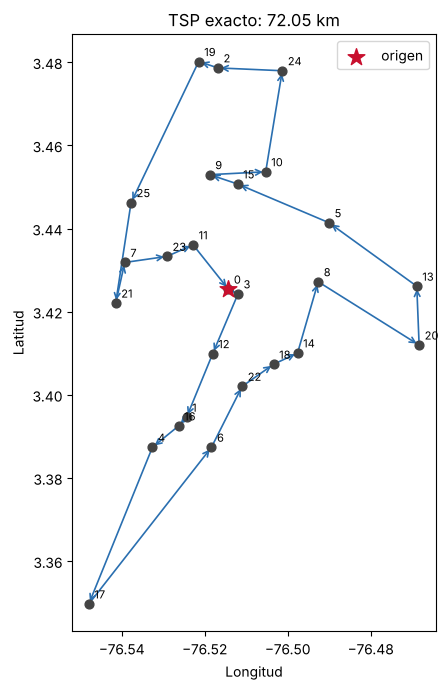

In [7]:
def dibujar_ruta(df, ruta, titulo):
    fig, ax = plt.subplots(figsize=(7, 7))
    lon, lat = df.longitud.values, df.latitud.values
    ax.scatter(lon, lat, s=40, c="#444", zorder=3)
    for i, nombre in enumerate(df.nombre):
        ax.annotate(str(i), (lon[i], lat[i]), xytext=(4, 4), textcoords="offset points", fontsize=8)
    for a, b in zip(ruta[:-1], ruta[1:]):
        ax.annotate("", xy=(lon[b], lat[b]), xytext=(lon[a], lat[a]),
                    arrowprops=dict(arrowstyle="->", color="#2a6fb0", lw=1.2), zorder=2)
    ax.scatter([lon[ruta[0]]], [lat[ruta[0]]], s=160, marker="*", c="#c8102e", zorder=4, label="origen")
    ax.set_title(titulo); ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud"); ax.legend()
    ax.set_aspect(1 / math.cos(math.radians(float(lat.mean()))))
    plt.tight_layout(); plt.show()

dibujar_ruta(tiendas, r_tsp["ruta"], f"TSP exacto: {r_tsp['valor']:.2f} km")

## 7. Exportar resultados

Genera un Excel con las distancias, los resultados del TSP y del m-TSP, y el camino mínimo.

In [8]:
def exportar_excel(ruta_archivo="resultados_optimizacion.xlsx"):
    with pd.ExcelWriter(ruta_archivo, engine="openpyxl") as w:
        pd.DataFrame(D_cali, index=nombres_cali, columns=nombres_cali).to_excel(w, sheet_name="Distancias_km")
        pd.DataFrame({"orden": range(len(r_tsp["ruta"])),
                      "punto": [nombres_cali[i] for i in r_tsp["ruta"]]}).to_excel(w, sheet_name="TSP", index=False)
        pd.DataFrame(r_m2["rutas"]).to_excel(w, sheet_name="mTSP_2", index=False)
        pd.DataFrame([{"origen": nombres_cali[r_cam["ruta"][0]], "destino": nombres_cali[r_cam["ruta"][-1]],
                       "km": r_cam["valor"], "ruta": " > ".join(nombres_cali[i] for i in r_cam["ruta"])}]).to_excel(w, sheet_name="Camino", index=False)
    return ruta_archivo

print("Archivo generado:", exportar_excel())

Archivo generado: resultados_optimizacion.xlsx


## 8. Verificación y límites

**Verificación.** Para instancias pequeñas se comprueba el óptimo contra fuerza bruta. Con 8 puntos, el TSP y el m-TSP deben coincidir exactamente.

**Límites del método.**
- El modelo exacto crece rápido con el número de puntos. Para 26 puntos el TSP resuelve en segundos; con cientos de puntos conviene usar otro enfoque, y la aplicación lo indicará con el estado «detenido por tiempo».
- Si el solver se detiene por tiempo, la brecha informada indica qué tan lejos puede estar del óptimo. Una brecha de 0 significa que el óptimo está demostrado.
- Las distancias son las que usted cargue. Si usa Haversine con factor vial, el resultado es una aproximación de la distancia por carretera.

In [9]:
def fuerza_bruta_tsp(D):
    n = D.shape[0]
    mejor = min(sum(D[a, b] for a, b in zip((0,) + p, p + (0,))) for p in itertools.permutations(range(1, n)))
    return mejor

rng = np.random.default_rng(1)
P = rng.random((8, 2))
D8 = np.linalg.norm(P[:, None] - P[None], axis=2)
ref = fuerza_bruta_tsp(D8)
t8 = resolver_tsp(D8)
print("TSP 8 puntos -> exacto:", round(t8["valor"], 6), "| fuerza bruta:", round(ref, 6),
      "| coincide:", abs(t8["valor"] - ref) < 1e-6)

TSP 8 puntos -> exacto: 2.540816 | fuerza bruta: 2.540816 | coincide: True
